#Домашнее задание №3: исследование KNN

**Цель задания** — самостоятельно исследовать метод k-ближайших соседей (KNN) самостоятельно исследовать метод k-ближайших соседей (KNN) на реальном датасете и сравнить его с несколькими базовыми
моделями.

Важное ограничение
Старайтесь выполнять задание  преимущественно без использования GPT / Copilot для написания решения. Лучше использовать:
документацию библиотек,
материалы лекций,
собственные заметки,
встроенную документацию Python (help()).


Задача — пройти основные этапы небольшого ML-проекта и понять, когда KNN работает хорошо, а когда — хуже других моделей когда KNN работает хорошо, а когда — хуже других моделей.

# 1. Загрузка данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from matplotlib.colors import ListedColormap
from scipy.stats import kstest, norm
from collections import Counter
import warnings
import os
import kagglehub
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from enum import unique
import time

In [ ]:
path = kagglehub.dataset_download("uciml/red-wine-quality-cortez-et-al-2009")

print("Path to dataset files:", path)

fiels=os.listdir(path)
print("Файл в папаке:",fiels)

csv_file = [f for f in fiels if f.endswith('.csv')][0]
full_path = os.path.join(path, csv_file)

Using Colab cache for faster access to the 'red-wine-quality-cortez-et-al-2009' dataset.
Path to dataset files: /kaggle/input/red-wine-quality-cortez-et-al-2009
Файл в папаке: ['winequality-red.csv']


In [ ]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12
pd.set_option('display.max_columns', None)
sns.set(font_scale=1.2)

# 1. Загрузка данных
print("1. Загрузка данных...")
df = pd.read_csv(full_path)

1. Загрузка данных...


In [ ]:
df.head(5)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


# 2. Первичный анализ данных (EDA)

In [ ]:
print("\n Основные характеристики датасета:")
print("\n Размер:",df.shape)
print("\nКоличество записей:\n", df.count())


 Основные характеристики датасета:

 Размер: (1599, 12)

Количество записей:
 fixed acidity           1599
volatile acidity        1599
citric acid             1599
residual sugar          1599
chlorides               1599
free sulfur dioxide     1599
total sulfur dioxide    1599
density                 1599
pH                      1599
sulphates               1599
alcohol                 1599
quality                 1599
dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [ ]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


Категориальных данных нет!

In [ ]:
df.dtypes

,0
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [ ]:
mis_val=df.isnull().sum()
col_mis_val=mis_val[mis_val>0]

if col_mis_val.empty:
    print("\nВ датафрейме нет пропусков")
else:
    print(col_mis_val)

if not col_mis_val.empty:
  for col in col_mis_val.index:
    if df[col].dtype in ['int64','float64']:
      df[col]=df[col].fillna(df[col].median())
    elif df[col].dtype in ['object']:
      df[col]=df[col].fillna(df[col].moda()[0])
    else:
      print("\nВ датафрейме нет пропущенных значений, поэтому заполнение не требуется.")




В датафрейме нет пропусков


In [ ]:
df.corr()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


In [ ]:
df.value_counts(df['quality'])

,count
quality,
5,681
6,638
7,199
4,53
8,18
3,10


In [ ]:
df.value_counts(df['alcohol'])

,count
alcohol,
9.500000,139
9.400000,103
9.800000,78
9.200000,72
10.000000,67
...,...
11.066667,1
13.500000,1
13.200000,1


In [ ]:
print(df['quality'].unique())
print(df['alcohol'].unique())

[5 6 7 4 8 3]
[ 9.4         9.8        10.          9.5        10.5         9.2
  9.9         9.1         9.3         9.          9.7        10.1
 10.6         9.6        10.8        10.3        13.1        10.2
 10.9        10.7        12.9        10.4        13.         14.
 11.5        11.4        12.4        11.         12.2        12.8
 12.6        12.5        11.7        11.3        12.3        12.
 11.9        11.8         8.7        13.3        11.2        11.6
 11.1        13.4        12.1         8.4        12.7        14.9
 13.2        13.6        13.5        10.03333333  9.55        8.5
 11.06666667  9.56666667 10.55        8.8        13.56666667 11.95
  9.95        9.23333333  9.25        9.05       10.75      ]


"Качество" вина чаще относится к 5 или 6, и реже к 3 или 8. Что показывает дисбаланс классов.

Содержание алкоголя более разнообразно, но тоже приемущественно равняется от 9 до 13.

Можем перенести случайно более высокий\низкий класс к среднему диапазону.Поэтому возможные проблемы возникают из-за дисбаланска класса "quality".


In [ ]:
class_percents = df.value_counts(normalize=True)*1000
print("\nОтносительные частоты (%):")
print(class_percents)



Относительные частоты (%):
fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density  pH    sulphates  alcohol  quality
6.7            0.460             0.24         1.7             0.077      18.0                 34.0                  0.99480  3.39  0.60       10.6     6          2.501563
7.2            0.360             0.46         2.1             0.074      24.0                 44.0                  0.99534  3.40  0.85       11.0     7          2.501563
7.5            0.510             0.02         1.7             0.084      13.0                 31.0                  0.99538  3.36  0.54       10.5     6          2.501563
7.2            0.695             0.13         2.0             0.076      12.0                 20.0                  0.99546  3.29  0.54       10.1     5          2.501563
8.3            0.650             0.10         2.9             0.089      17.0                 40.0                  0.99803  3.29

In [ ]:
if class_percents.min() < 20:
    print("\n Сильный дисбаланс классов!")


 Сильный дисбаланс классов!


<Axes: >

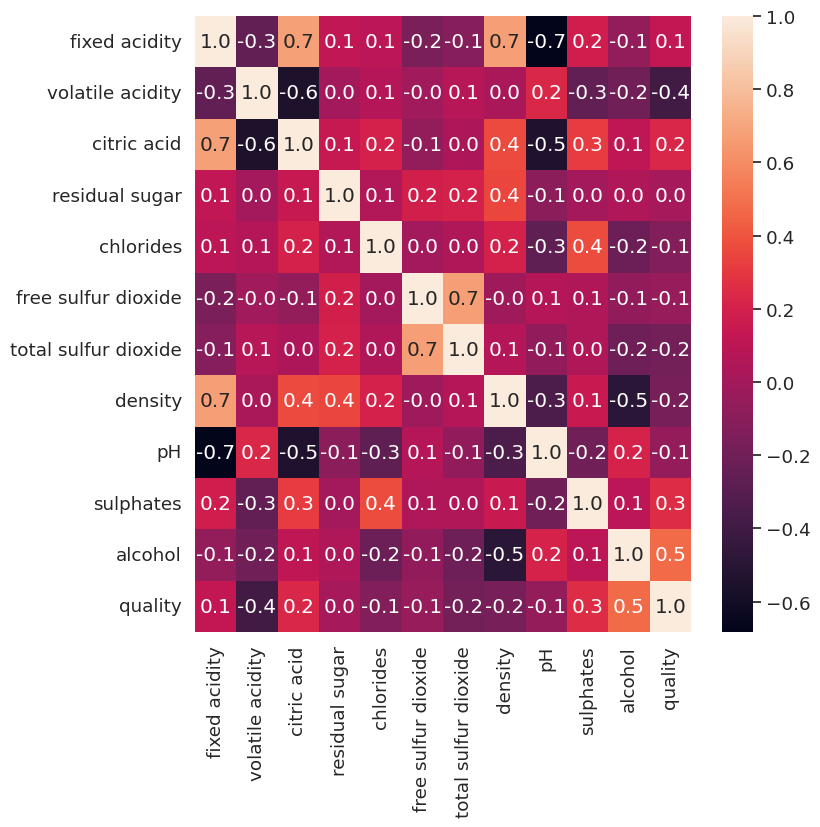

In [ ]:
fig,ax=plt.subplots(figsize=(8,8))
sns.heatmap(df.corr(),annot=True,fmt=".1f")

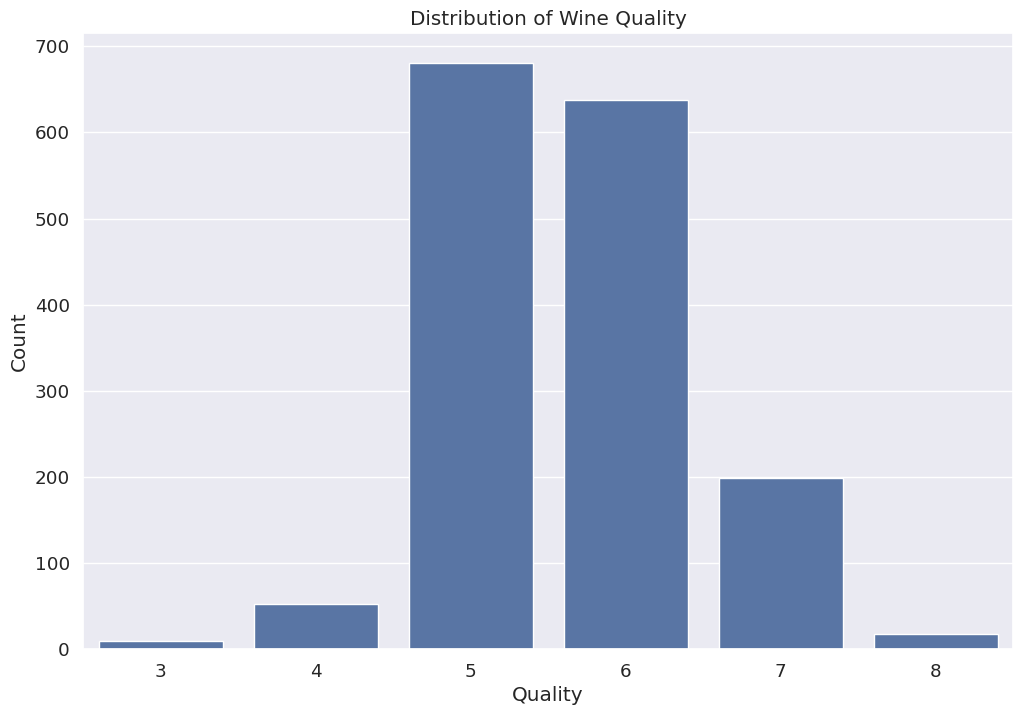

In [ ]:
sns.countplot(x='quality', data=df)
plt.title('Distribution of Wine Quality')
plt.xlabel('Quality')
plt.ylabel('Count')
plt.show()

In [ ]:
print(df.columns.tolist())

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


<Axes: xlabel='quality', ylabel='alcohol'>

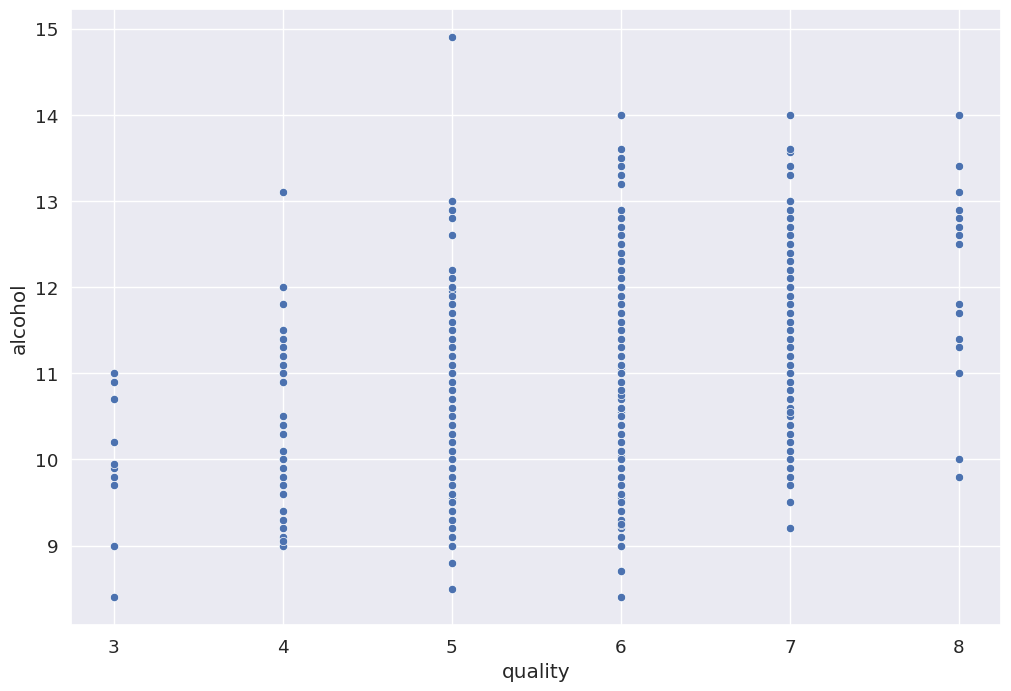

In [ ]:
sns.scatterplot(data=df,x="quality",y="alcohol")

<Axes: xlabel='citric acid', ylabel='fixed acidity'>

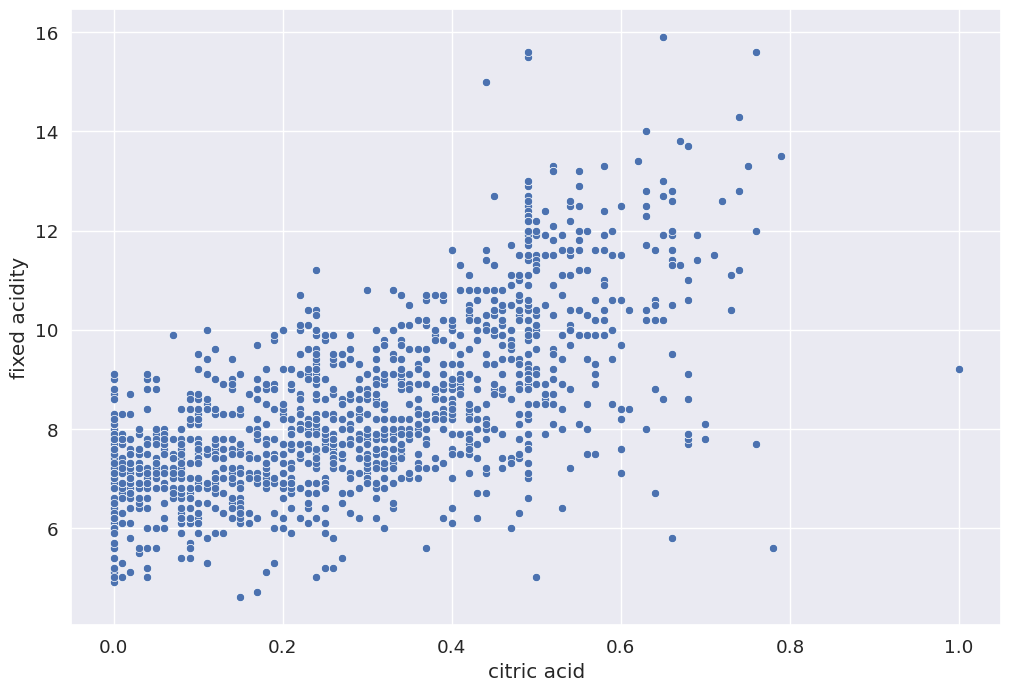

In [ ]:
sns.scatterplot(data=df,x="citric acid",y="fixed acidity")

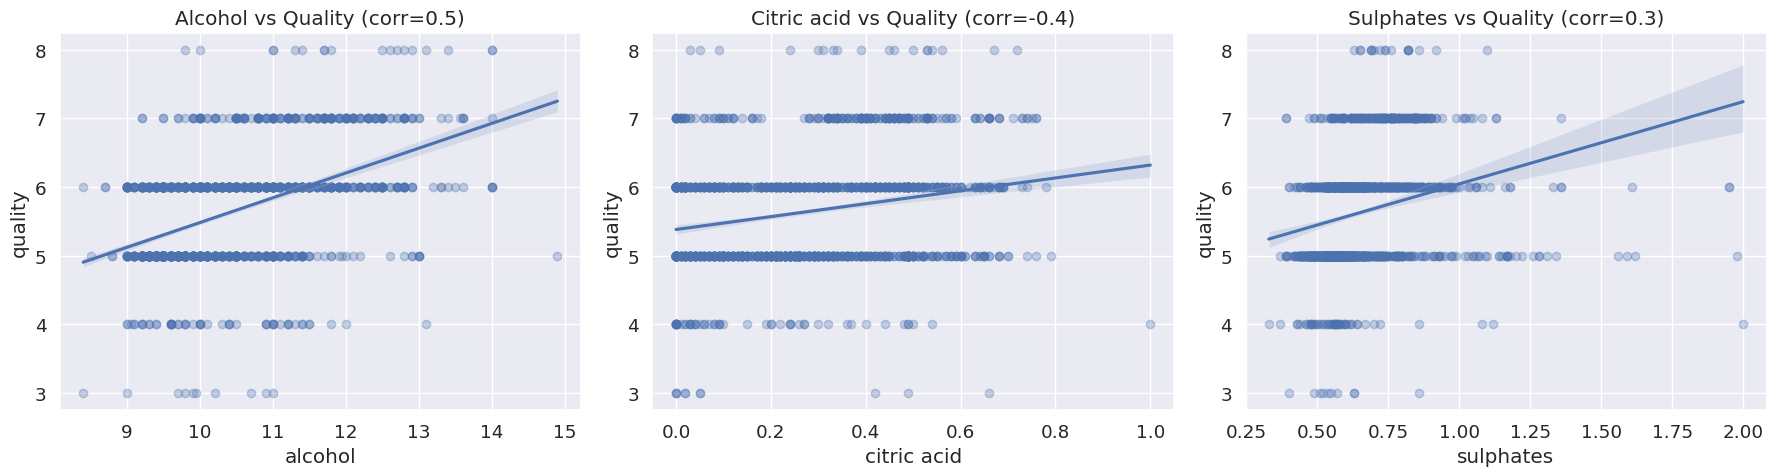

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.regplot(data=df, x='alcohol', y='quality', ax=axes[0], scatter_kws={'alpha':0.3})
axes[0].set_title('Alcohol vs Quality (corr=0.5)')

sns.regplot(data=df, x='citric acid', y='quality', ax=axes[1], scatter_kws={'alpha':0.3})
axes[1].set_title('Citric acid vs Quality (corr=-0.4)')

sns.regplot(data=df, x='sulphates', y='quality', ax=axes[2], scatter_kws={'alpha':0.3})
axes[2].set_title('Sulphates vs Quality (corr=0.3)')

plt.tight_layout()
plt.show()

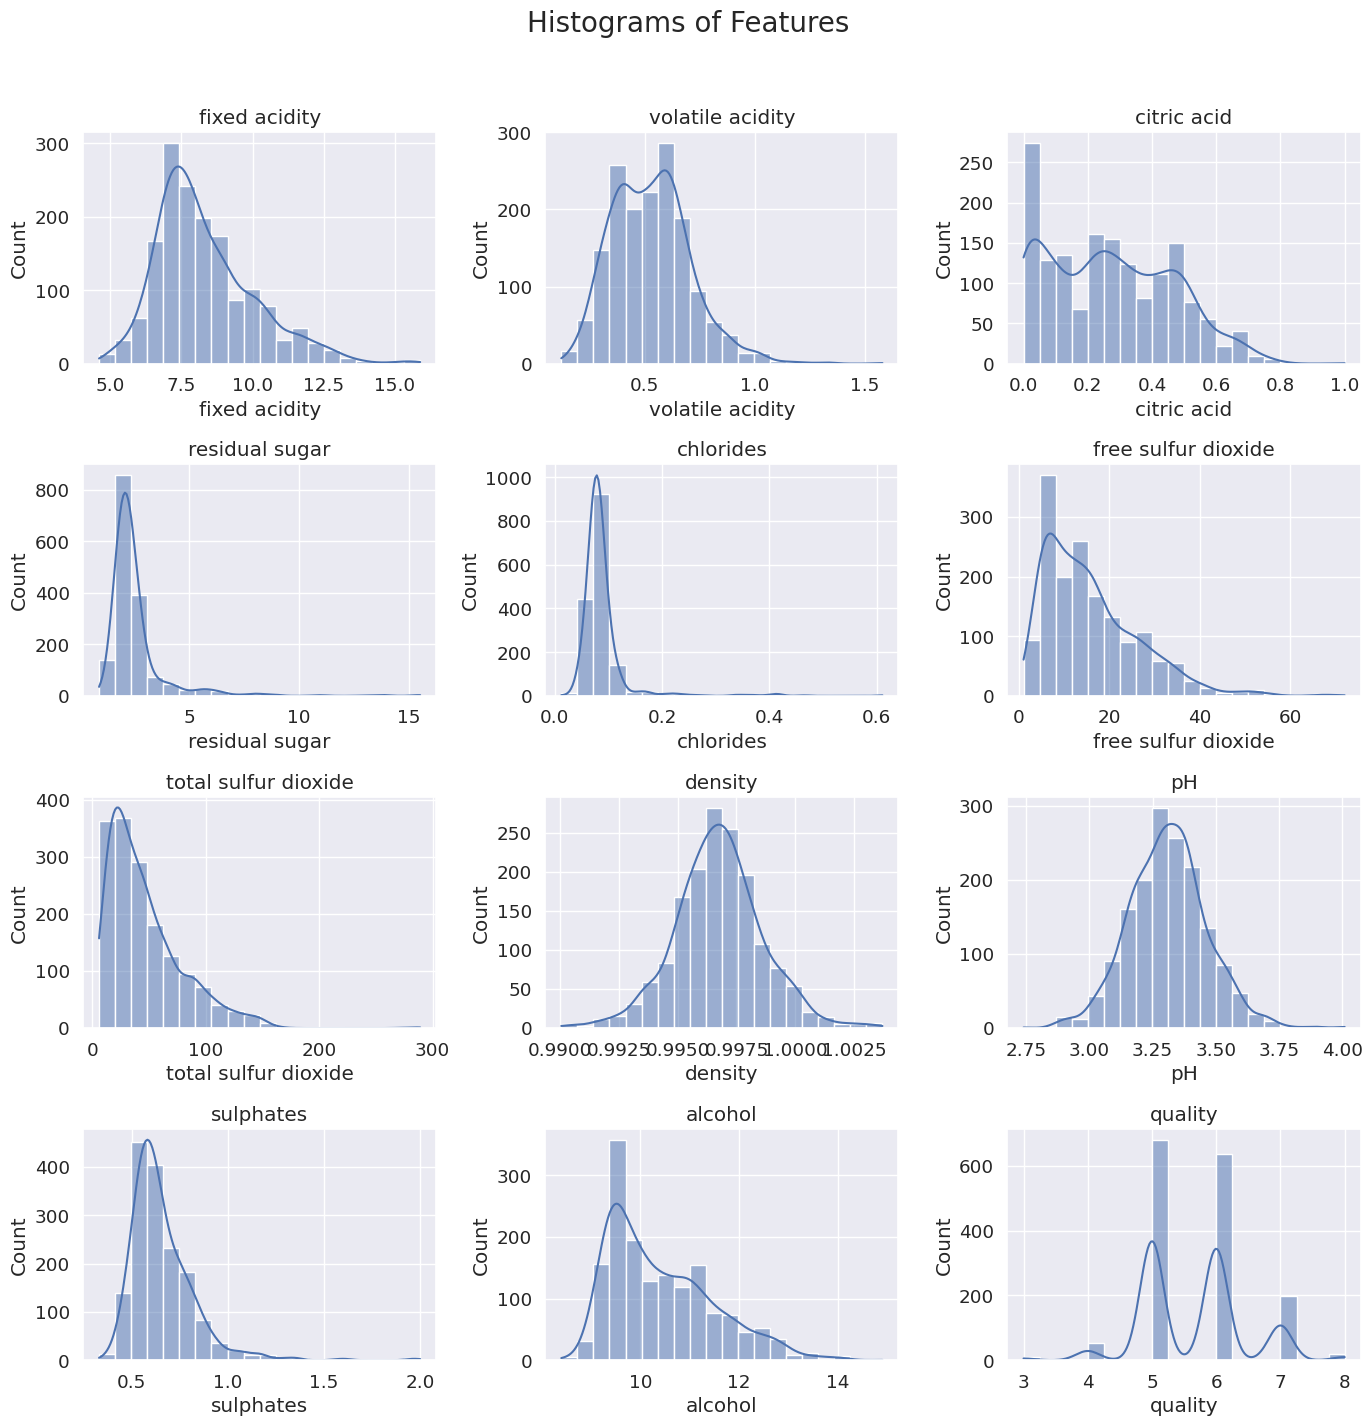

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(14, 14))
axes = axes.flat


for i, column in enumerate(df.columns):
    if i < len(axes):

        sns.histplot(data=df, x=column, ax=axes[i], kde=True, bins=20)
        axes[i].set_title(column)
    else:
        axes[i].set_visible(False)

plt.suptitle('Histograms of Features', size=20, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
alc_group=[6.0, 8.7, 9.9, 11.9, 12.8, 15.5]
lables=['Очень слабое','Слабое', 'Среднее', 'Крепкое', 'Очень крепкое']
df['alcgroup']=pd.cut(x=df['alcohol'], bins= alc_group, labels=lables)
pd.crosstab(df['quality'], df['alcgroup'])

alcgroup,Очень слабое,Слабое,Среднее,Крепкое,Очень крепкое
quality,,,,,
3,1,4,5,0,0
4,0,24,27,1,1
5,1,445,222,6,7
6,3,189,373,60,13
7,0,11,122,54,12
8,0,1,8,4,5


In [ ]:
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,alcgroup
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,Слабое
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,Слабое
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,Слабое
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,Слабое
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,Слабое
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,Среднее
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,Среднее
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,Среднее
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,Среднее


In [ ]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'alcgroup'],
      dtype='object')

In [ ]:
q1=df['density'].quantile(0.25)
q3=df['density'].quantile(0.75)

iqr = q3 - q1

lower= q1 - 1.5 * iqr
hight= q3 + 1.5 * iqr

print(f'Density: \n Нижняя граница:{lower} \n Верхняя граница:{hight}')

Density: 
 Нижняя граница:0.9922475000000001 
 Верхняя граница:1.0011875


In [ ]:
out_hight=(df['density'] > hight).sum()
out_lower=(df['density'] < lower).sum()

total_outliers = out_hight + out_lower

print(f"Выбросов сверху: {out_hight}")
print(f"Выбросов снизу (отрицательные): {out_lower}")
print(f"Всего выбросов: {total_outliers}")

Выбросов сверху: 24
Выбросов снизу (отрицательные): 21
Всего выбросов: 45


In [ ]:
q1=df['free sulfur dioxide'].quantile(0.25)
q3=df['free sulfur dioxide'].quantile(0.75)

iqr = q3 - q1

lower= q1 - 1.5 * iqr
hight= q3 + 1.5 * iqr

print(f'Free sulfur dioxide: \n Нижняя граница:{lower} \n Верхняя граница:{hight}')

Free sulfur dioxide: 
 Нижняя граница:-14.0 
 Верхняя граница:42.0


In [ ]:
out_hight=(df['free sulfur dioxide'] > hight).sum()
out_lower=(df['free sulfur dioxide'] < lower).sum()

total_outliers = out_hight + out_lower

print(f"Выбросов сверху: {out_hight}")
print(f"Выбросов снизу (отрицательные): {out_lower}")
print(f"Всего выбросов: {total_outliers}")

Выбросов сверху: 30
Выбросов снизу (отрицательные): 0
Всего выбросов: 30


In [ ]:
df_clean = df[
    (df['density'] >= 0.9922) & (df['density'] <= 1.0011) &
    (df['free sulfur dioxide'] >= 0.0) & (df['free sulfur dioxide'] <= 42.0)
]

In [ ]:
df_clean

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,alcgroup
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,Слабое
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,Слабое
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,Слабое
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,Слабое
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,Слабое
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,Среднее
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,Среднее
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,Среднее
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,Среднее


#3. Подготовка данных

In [ ]:
print("Дубликатов:", df_clean.duplicated().sum())
data = df_clean.drop_duplicates()

Дубликатов: 228


In [ ]:

X = data.drop(['quality', 'alcgroup'],axis=1)
y = data['quality'].round().astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


Маштабирование обязательного для того чтобы приобработке данных не случилась потеря (утечка данных\признаков). Потому что данные могут быть как очень большие так и одновременно очень маленькими, и какой-то из признаков будет игнорироваться.
Тестовая выборка помогает нам протестировать модель\алгоритм который мы обучили на тренеровочном и если мы подберем от туда параметры то оценка модели станет бесмысленной (она может знать некоторые данные).

# 4.1 Обучение LogisticRegression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

log_model = Pipeline([('scaler', StandardScaler()),
                      ('model', LogisticRegression(max_iter=3000))])
grid_cv = GridSearchCV(log_model, {'model__C': [0.01, 0.1, 1, 10, 100]}, cv=cv, scoring='accuracy', n_jobs=-1)

In [ ]:
grid_cv.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model',
                                        LogisticRegression(max_iter=3000))]),
             n_jobs=-1, param_grid={'model__C': [0.01, 0.1, 1, 10, 100]},
             scoring='accuracy')

In [ ]:
print(f'LogReg: {grid_cv.best_params_} || CV :{grid_cv.best_score_:.4f}')

LogReg: {'model__C': 10} || CV :0.5697


In [ ]:
# до подбора параметров
models = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'KNN (k=5)': Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())]),
    'LogReg': Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=2000))])
}

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Dummy: 0.4336 (+/- 0.0009)
KNN (k=5): 0.5072 (+/- 0.0208)
LogReg: 0.5642 (+/- 0.0155)


# 4. Обучение KNN

Увклидова метрика:

$d(a, b) = \sqrt{\sum_{i=1}^n (a_i - b_i)^2}$

Минковского

$d(a, b) = (\sum_{i=1}^n |a_i - b_i|^p)^\frac{1}{p}$

Манхэтанская:

$d(a, b) = \sum_{i=1}^n |a_i - b_i|$

Косинусное расстояние

$d(a, b) = 1 - \frac{\sum_{i=1}^n a_i b_i}{\sqrt{\sum_{i=1}^n a_i^2} \sqrt{\sum_{i=1}^n b_i^2}}$




In [ ]:
k_list= range(1, 28)
train_accur = []
cv_accu = []

for k in k_list:
  pipe = Pipeline([('scaler', StandardScaler()),
                   ('knn', KNeighborsClassifier(n_neighbors=k))])
  cv_accu.append(cross_val_score(pipe, X_train, y_train,cv=cv).mean())
  pipe.fit(X_train, y_train)
  train_accur.append(pipe.score(X_train, y_train))

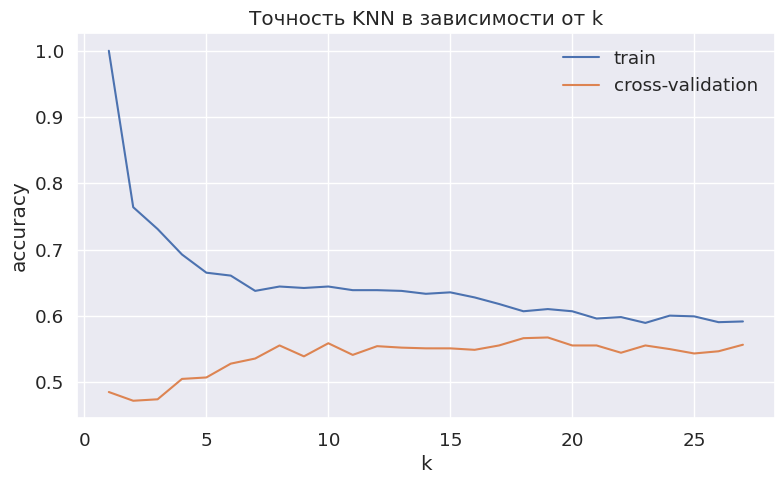

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(k_list, train_accur, label='train')
plt.plot(k_list, cv_accu, label='cross-validation')
plt.xlabel('k')
plt.ylabel('accuracy')
plt.title('Точность KNN в зависимости от k')
plt.legend()
plt.show()

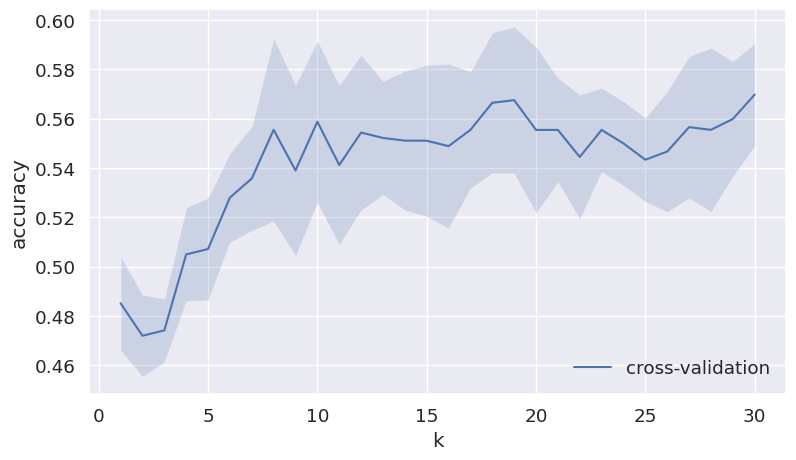

In [ ]:
k_list = range(1, 31)
cv_mean = []
cv_std = []

for k in k_list:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=k))])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv)
    cv_mean.append(scores.mean())
    cv_std.append(scores.std())

cv_mean = np.array(cv_mean)
cv_std = np.array(cv_std)

plt.figure(figsize=(9, 5))
plt.plot(k_list, cv_mean, label='cross-validation')
plt.fill_between(k_list, cv_mean - cv_std, cv_mean + cv_std, alpha=0.2)
plt.xlabel('k')
plt.ylabel('accuracy')
plt.legend()
plt.show()

In [ ]:
for k in [5, 10, 19, 30]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=k))])
    acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy').mean()
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro').mean()
    print(f"k={k:2d} | accuracy: {acc:.4f} | macro-F1: {f1:.4f}")

k= 5 | accuracy: 0.5072 | macro-F1: 0.2501
k=10 | accuracy: 0.5588 | macro-F1: 0.2654
k=19 | accuracy: 0.5675 | macro-F1: 0.2617
k=30 | accuracy: 0.5697 | macro-F1: 0.2623


In [ ]:
def plot_decision_boundaries(X, y, model, ax=None, title="Decision Boundaries"):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))

    # Определяем границы графика с небольшим запасом
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    # Создаем сетку точек для построения границы
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))

    # Предсказываем класс для каждой точки сетки
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Определяем цветовую схему
    colors = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])

    # Отображаем границы решения
    ax.contourf(xx, yy, Z, alpha=0.4, cmap=colors)

    # Отображаем обучающие точки
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, s=80, edgecolor='k', cmap=colors)

    # Добавляем легенду
    legend1 = ax.legend(*scatter.legend_elements(), title="Классы")
    ax.add_artist(legend1)

    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_title(title)
    ax.set_xlabel('Признак 1')
    ax.set_ylabel('Признак 2')

    return ax

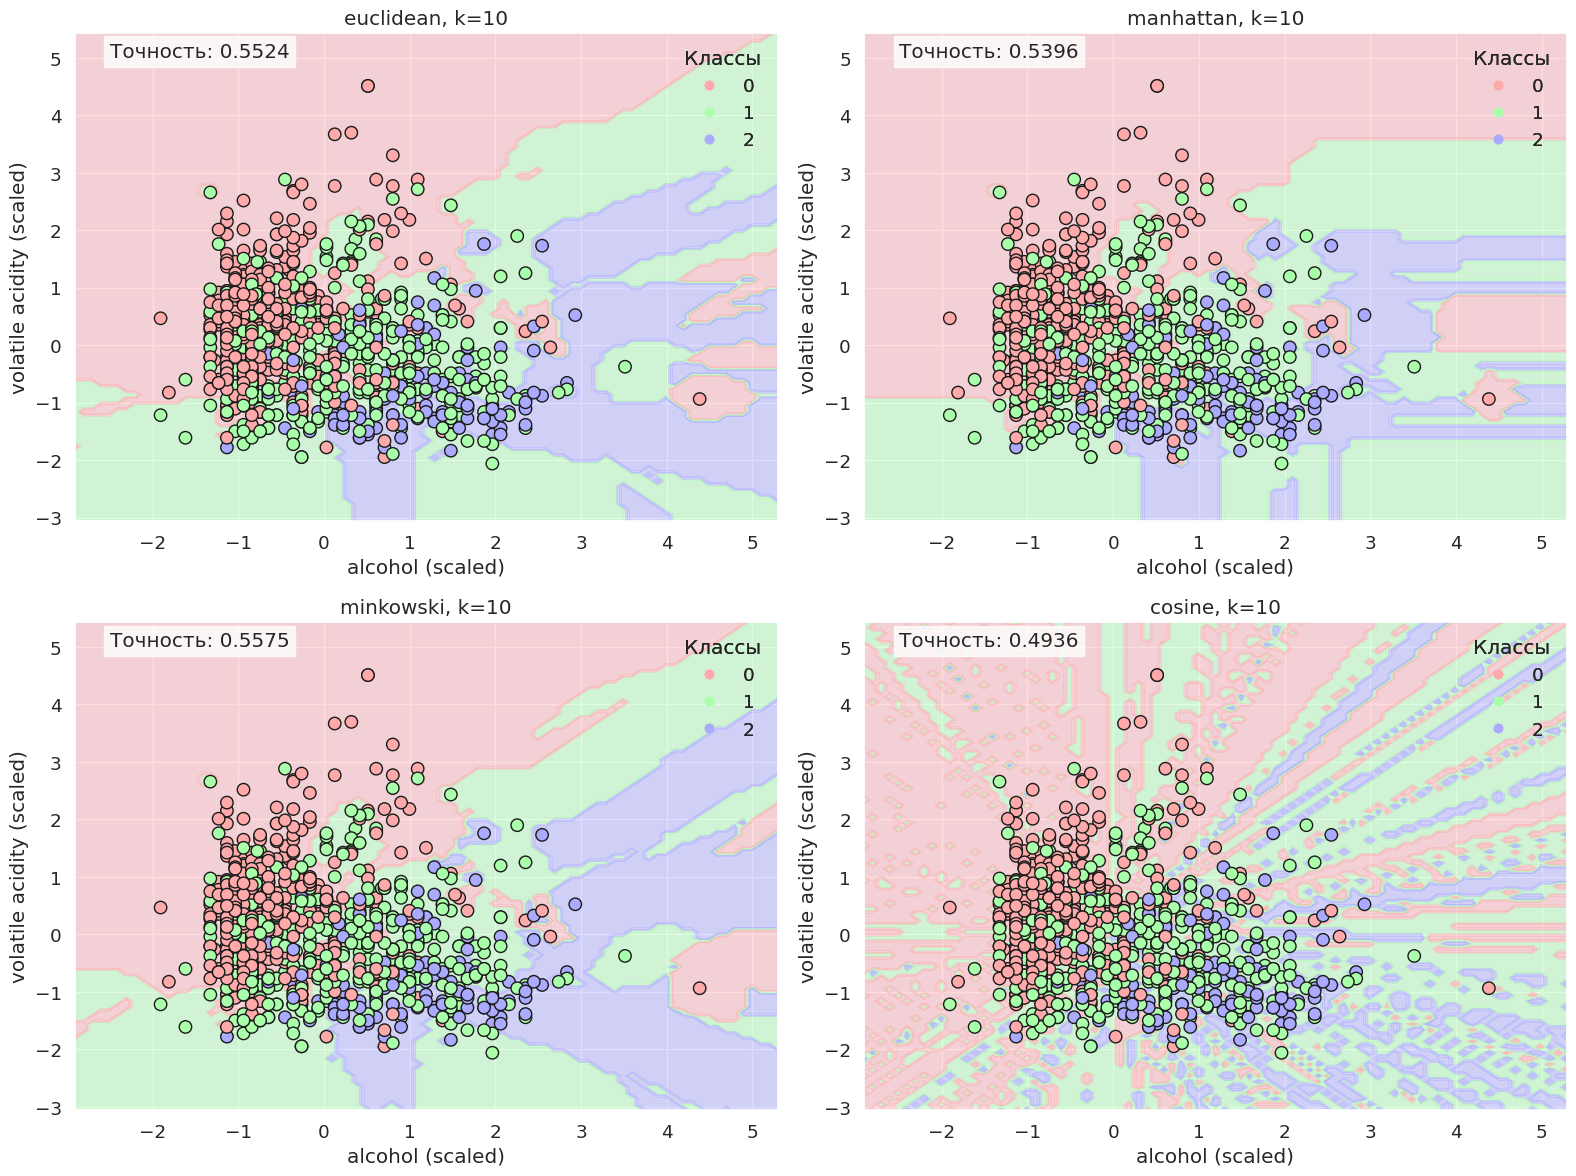

In [ ]:
cols = ['alcohol', 'volatile acidity']

# 3 класса: 0 - плохое, 1 - среднее, 2 - хорошее
y3 = pd.cut(y, bins=[0, 5, 6, 10], labels=[0, 1, 2]).astype(int)

X2_train, X2_test, y3_train, y3_test = train_test_split(
    X[cols], y3, test_size=0.3, random_state=42, stratify=y3)

scaler2 = StandardScaler()
X2_train_s = scaler2.fit_transform(X2_train)
X2_test_s = scaler2.transform(X2_test)

metrics = ['euclidean', 'manhattan', 'minkowski', 'cosine']
k = 10

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for i, metric in enumerate(metrics):
    p = 3 if metric == 'minkowski' else 2

    knn2 = KNeighborsClassifier(n_neighbors=k, weights='distance', metric=metric, p=p)
    knn2.fit(X2_train_s, y3_train)

    plot_decision_boundaries(X2_train_s, y3_train, knn2, ax=axes.flat[i],
                             title=f'{metric}, k={k}')
    axes.flat[i].set_xlabel('alcohol (scaled)')
    axes.flat[i].set_ylabel('volatile acidity (scaled)')

    accuracy = knn2.score(X2_test_s, y3_test)
    axes.flat[i].text(0.05, 0.95, f'Точность: {accuracy:.4f}', transform=axes.flat[i].transAxes,
                      bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

## Потбор гиперпараметров

In [ ]:
pipe = Pipeline([('scaler', StandardScaler()),
                 ('knn', KNeighborsClassifier())])

# metric оставляем по умолчанию (minkowski): p=1 это Манхэттен, p=2 это Евклид
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

grid_knn = GridSearchCV(pipe, param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid_knn.fit(X_train, y_train)

print("Лучшие параметры:", grid_knn.best_params_)
print(f"CV accuracy: {grid_knn.best_score_:.4f}")

Лучшие параметры: {'knn__n_neighbors': 21, 'knn__p': 2, 'knn__weights': 'distance'}
CV accuracy: 0.5664


## Оценка качества: Confusion Matrix

Accuracy: 0.5985
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        18
           5       0.65      0.80      0.72       161
           6       0.56      0.57      0.56       157
           7       0.47      0.32      0.38        50
           8       0.00      0.00      0.00         3

    accuracy                           0.60       391
   macro avg       0.28      0.28      0.28       391
weighted avg       0.55      0.60      0.57       391



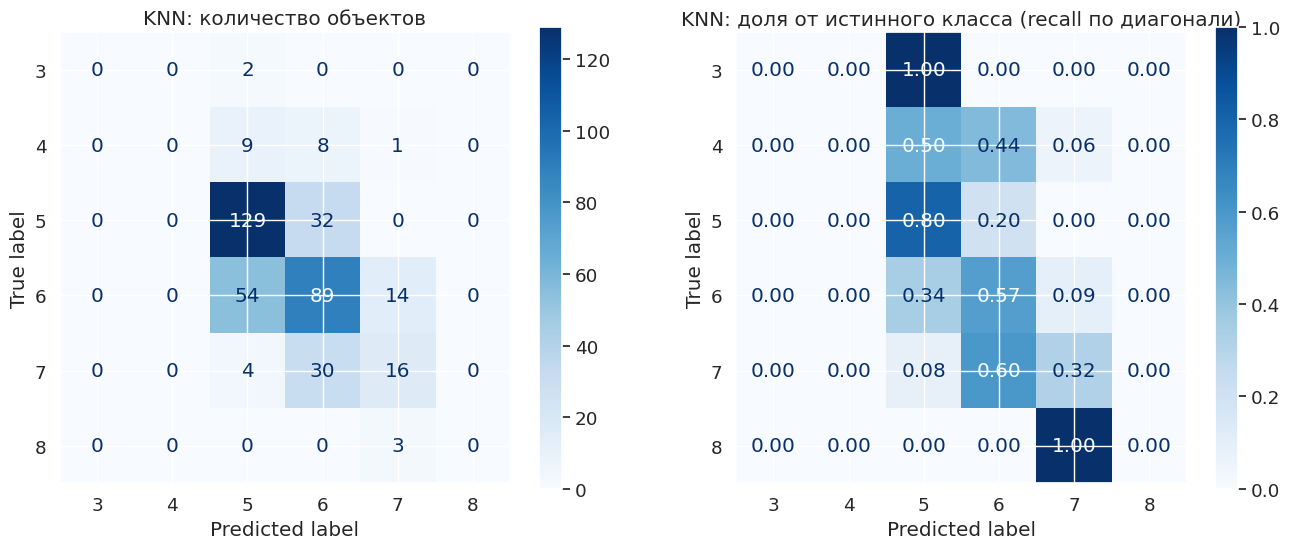

In [ ]:
best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 4))
print(classification_report(y_test, y_pred_knn, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
cm = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(cm, display_labels=best_knn.classes_).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('KNN: количество объектов')

cm_norm = confusion_matrix(y_test, y_pred_knn, normalize='true')
ConfusionMatrixDisplay(cm_norm, display_labels=best_knn.classes_).plot(ax=axes[1], cmap='Blues', values_format='.2f')
axes[1].set_title('KNN: доля от истинного класса (recall по диагонали)')
plt.show()

## Финальное сравнение результатов моделей

In [ ]:
final_models = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'KNN': grid_knn.best_estimator_,
    'LogReg': grid_cv.best_estimator_
}

rows = []
for name, model in final_models.items():
    start = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - start

    start = time.time()
    pred = model.predict(X_test)
    pred_time = time.time() - start

    rows.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'balanced_acc': balanced_accuracy_score(y_test, pred),
        'f1_macro': f1_score(y_test, pred, average='macro', zero_division=0),
        'fit_time': fit_time,
        'predict_time': pred_time
    })

results_final = pd.DataFrame(rows)
print(results_final.round(4))

    model  accuracy  balanced_acc  f1_macro  fit_time  predict_time
0   Dummy    0.4118        0.1667    0.0972    0.0022        0.0002
1     KNN    0.5985        0.2814    0.2772    0.0067        0.0192
2  LogReg    0.5882        0.3607    0.3638    0.1023        0.0046


## Тест моделей на данных с искусственным шумом

In [ ]:
rng = np.random.RandomState(42)

for n_noise in [0, 5, 10, 20, 40]:
    noise_train = rng.normal(size=(len(X_train), n_noise))
    noise_test = rng.normal(size=(len(X_test), n_noise))
    Xtr = np.hstack([X_train.values, noise_train])
    Xte = np.hstack([X_test.values, noise_test])

    knn = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(**{k.replace('knn__', ''): v for k, v in grid_knn.best_params_.items()}))])
    lr = Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=2000))])

    knn.fit(Xtr, y_train)
    lr.fit(Xtr, y_train)
    print(f"Шумовых признаков: {n_noise:2d} | KNN: {knn.score(Xte, y_test):.4f} | LogReg: {lr.score(Xte, y_test):.4f}")

Шумовых признаков:  0 | KNN: 0.5985 | LogReg: 0.5882
Шумовых признаков:  5 | KNN: 0.5499 | LogReg: 0.5857
Шумовых признаков: 10 | KNN: 0.5422 | LogReg: 0.6036
Шумовых признаков: 20 | KNN: 0.5550 | LogReg: 0.6010
Шумовых признаков: 40 | KNN: 0.5294 | LogReg: 0.5217


## Проверка качества на меньшем колличестве классов

In [ ]:
# плохое (<=5), среднее (6), хорошее (>=7)
y3 = pd.cut(y, bins=[0, 5, 6, 10], labels=[0, 1, 2]).astype(int)
X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X, y3, test_size=0.3, random_state=42, stratify=y3)

for name in ['KNN', 'LogReg']:
    model = final_models[name]
    model.fit(X_train3, y_train3)
    pred3 = model.predict(X_test3)
    print(name, "accuracy:", round(accuracy_score(y_test3, pred3), 4),
          "macro-F1:", round(f1_score(y_test3, pred3, average='macro'), 4))

KNN accuracy: 0.5882 macro-F1: 0.5353
LogReg accuracy: 0.6036 macro-F1: 0.5527


## Выводы по результатам исследования KNN

На основе проведенного анализа и экспериментов на датасете качества красного вина можно сделать следующие ключевые выводы о применимости, преимуществах и ограничениях метода $k$-ближайших соседей (KNN):

### 1. Преимущества KNN перед другими моделями (например, логистической регрессией):
* **Простота и отсутствие этапа обучения:** KNN является «ленивым» классификатором (lazy learner). Модель не строит глобальную параметрическую функцию, а просто запоминает обучающую выборку. Время «обучения» минимально (близко к нулю), что подтверждается метрикой `fit_time` в нашей сравнительной таблице.
* **Нелинейные границы принятия решений:** В отличие от логистической регрессии, которая по умолчанию строит линейные разделяющие гиперплоскости, KNN отлично справляется со сложными нелинейными структурами данных. Это наглядно видно на построенных графиках разделяющих границ (Decision Boundaries) для алкоголя и кислотности.
* **Гибкость настроек:** С помощью изменения метрик расстояния (Евклидово, Манхэттенское, Минковского, косинусное) и весов соседей (`weights='distance'`) алгоритм можно тонко адаптировать под геометрию конкретного признакового пространства.

### 2. В каких случаях KNN превосходит другие модели:
* **Локальная структура данных:** Когда объекты одного класса расположены кучно (образуют компактные кластеры) в признаковом пространстве, KNN работает исключительно хорошо.
* **Малое количество признаков высокой значимости:** При небольшом количестве хорошо интерпретируемых и масштабированных признаков KNN показывает высокую точность.
* **Мультиклассовая классификация без усложнения модели:** KNN естественным образом работает с любым количеством классов без необходимости настраивать схемы One-vs-Rest (как в логистической регрессии).

### 3. Слабые стороны KNN :
* **Чувствительность к  размерности и шуму:** мой эксперимент с искусственным шумом наглядно показал, что при добавлении шумовых признаков (от 5 до 40) точность KNN падает значительно быстрее, чем у логистической регрессии (с 0.5985 до 0.5294). Лишние признаки искажают расстояния между точками.
* **Дисбаланс классов:** Из-за сильного дисбаланса в качестве вина (классы 5 и 6 доминируют) стандартный KNN часто голосует за мажоритарные классы, из-за чего recall для редких классов (3, 4, 8) падает до нуля.
* **Медленный инференс:** Время предсказания (`predict_time`) у KNN заметно выше, чем у логистической регрессии, так как для каждого нового объекта модели приходится вычислять расстояния до всех точек обучающей выборки.